# Importing Libraries

In [5]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

# Mounting Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# Define path
data_dir = "/content/drive/MyDrive/updated_final_skin_issue_dataset"
train_dir = os.path.join(data_dir, 'train')

# Identify classes
classes = sorted(os.listdir(train_dir))

# Exploratory Data Analysis (EDA)

### Data Distribution

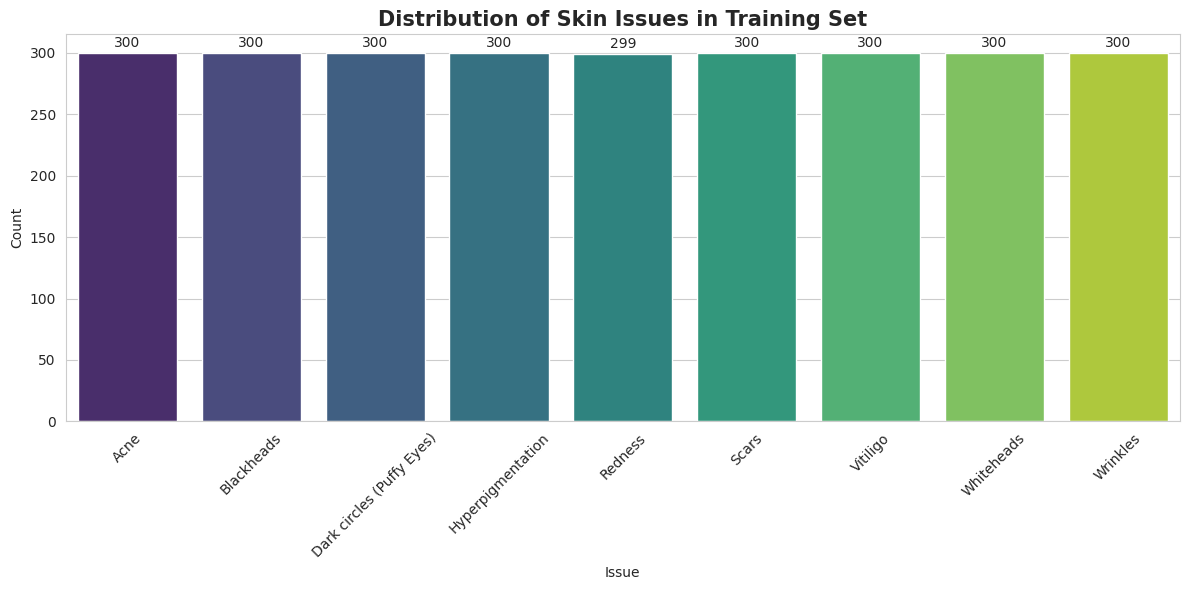

In [13]:
# Count images per class
stats = []
for cls in classes:
    path = os.path.join(train_dir, cls)
    if os.path.isdir(path):
        count = len([f for f in os.listdir(path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
        stats.append({'Issue': cls, 'Count': count})

df_issues = pd.DataFrame(stats)

# Plotting Distribution
plt.figure(figsize=(12, 6))
sns.set_style("whitegrid")
ax = sns.barplot(data=df_issues, x='Issue', y='Count', hue='Issue', palette='viridis', legend=False)
plt.title('Distribution of Skin Issues in Training Set', fontsize=15, fontweight='bold')
plt.xticks(rotation=45)

# Annotate counts
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='center', xytext=(0, 7), textcoords='offset points')

plt.tight_layout()
plt.show()

### Visual Inspection of Classes

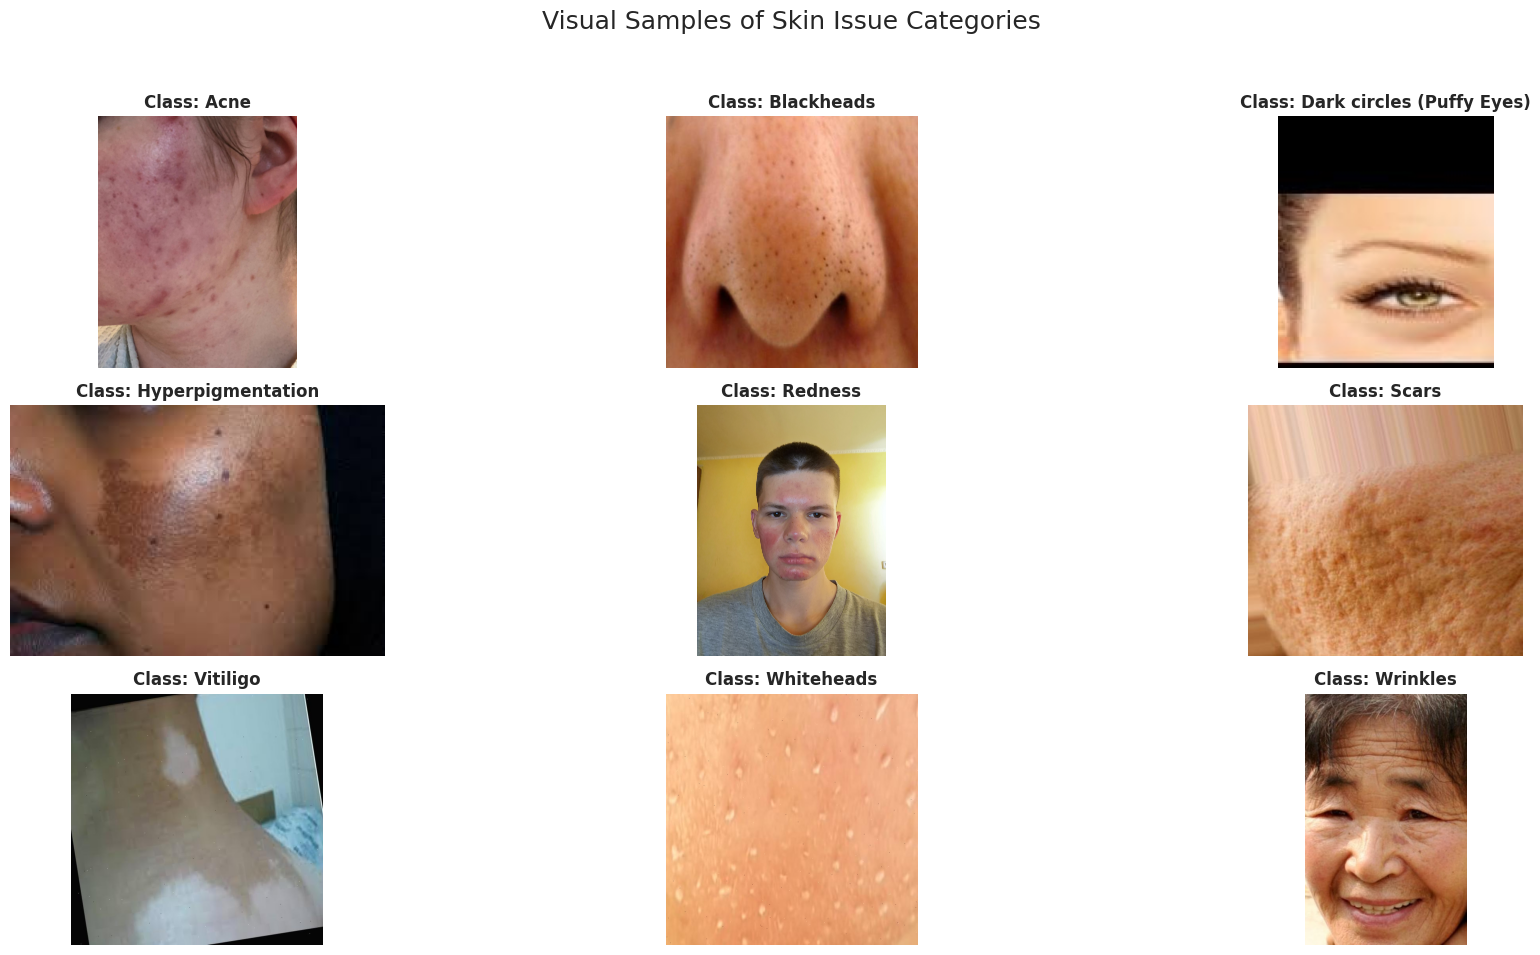

In [11]:
# Function to plot samples of each skin issue
def plot_issue_samples(directory, issue_list):
    plt.figure(figsize=(20, 10))
    for i, issue in enumerate(issue_list):
        issue_path = os.path.join(directory, issue)
        img_name = [f for f in os.listdir(issue_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))][0]
        img_path = os.path.join(issue_path, img_name)

        img = mpimg.imread(img_path)
        plt.subplot(3, 3, i + 1)
        plt.imshow(img)
        plt.title(f"Class: {issue}", fontsize=12, fontweight='bold')
        plt.axis('off')

    plt.suptitle("Visual Samples of Skin Issue Categories", fontsize=18)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

plot_issue_samples(train_dir, classes)

### Visualizing Augmentation Strategy

Applying augmentation strategy to a sample of 'Acne'


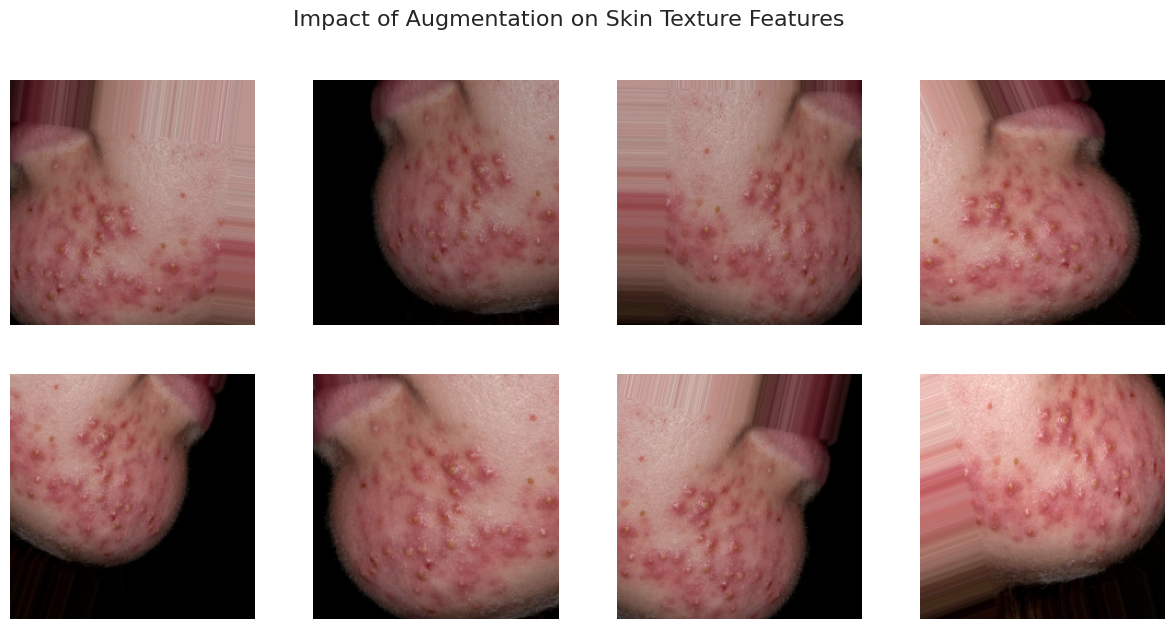

In [19]:
# Data Augmentation
datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    brightness_range=[0.8, 1.2]
)

# Load a sample image
sample_cls = "Acne"
sample_img_dir = os.path.join(train_dir, sample_cls)
sample_img_path = os.path.join(sample_img_dir, os.listdir(sample_img_dir)[26])

img = load_img(sample_img_path, target_size=(224, 224))
x = img_to_array(img)
x = x.reshape((1,) + x.shape) # Reshape to (1, 224, 224, 3)

# Generate augmented images
print(f"Applying augmentation strategy to a sample of '{sample_cls}'")
plt.figure(figsize=(15, 7))
i = 0
for batch in datagen.flow(x, batch_size=1):
    plt.subplot(2, 4, i + 1)
    plt.imshow(batch[0].astype('uint8'))
    plt.axis('off')
    i += 1
    if i == 8: break
plt.suptitle("Impact of Augmentation on Skin Texture Features", fontsize=16)
plt.show()